# CONUS Datetime Parsing and Basic Analytics

This notebook is a focused walkthrough of datetime parsing using real U.S. electricity demand data.

Dataset: conus_hourly_demand.csv (hourly, UTC timestamps).

## 1. Setup

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)
print("pandas", pd.__version__)

pandas 2.2.3


## 2. Load the CSV and inspect schema

In [2]:
csv_path = Path("conus_hourly_demand.csv")
if not csv_path.exists():
    raise FileNotFoundError(f"Missing file: {csv_path.resolve()}")

raw = pd.read_csv(csv_path, na_values=["MISSING", "EMPTY"])
print("shape:", raw.shape)
print("columns:", raw.columns.tolist())
raw.head()

shape: (43848, 3)
columns: ['date_time', 'raw demand (MW)', 'cleaned demand (MW)']


,date_time,raw demand (MW),cleaned demand (MW)
0,2015-07-02 00:00:00,559192.0,578291.0
1,2015-07-02 01:00:00,546894.0,567731.0
2,2015-07-02 02:00:00,535593.0,556167.0
3,2015-07-02 03:00:00,513328.0,533399.0
4,2015-07-02 04:00:00,478430.0,497969.0


## 3. Parse datetime column as UTC (core datetime step)

In [3]:
df = raw.copy()
df["timestamp_utc"] = pd.to_datetime(df["date_time"], errors="coerce", utc=True)

bad_ts = df["timestamp_utc"].isna().sum()
print("parsed timestamps:", len(df) - bad_ts)
print("invalid timestamps:", bad_ts)

df[["date_time", "timestamp_utc"]].head()

parsed timestamps: 43848
invalid timestamps: 0


,date_time,timestamp_utc
0,2015-07-02 00:00:00,2015-07-02 00:00:00+00:00
1,2015-07-02 01:00:00,2015-07-02 01:00:00+00:00
2,2015-07-02 02:00:00,2015-07-02 02:00:00+00:00
3,2015-07-02 03:00:00,2015-07-02 03:00:00+00:00
4,2015-07-02 04:00:00,2015-07-02 04:00:00+00:00


## 4. Datetime quality checks

In [4]:
df["cleaned_demand_mw"] = pd.to_numeric(df["cleaned demand (MW)"], errors="coerce")

work = df.dropna(subset=["timestamp_utc", "cleaned_demand_mw"]).copy()
work = work.sort_values("timestamp_utc")

dup_count = work["timestamp_utc"].duplicated().sum()
is_monotonic = work["timestamp_utc"].is_monotonic_increasing

dt_diffs = work["timestamp_utc"].diff().dropna()
mode_step = dt_diffs.mode().iloc[0]
hourly_like_ratio = (dt_diffs == pd.Timedelta(hours=1)).mean()

print("valid rows:", len(work))
print("duplicate timestamps:", int(dup_count))
print("monotonic increasing:", bool(is_monotonic))
print("most common step:", mode_step)
print("exact 1-hour step ratio:", round(float(hourly_like_ratio), 6))

valid rows: 43848
duplicate timestamps: 0
monotonic increasing: True
most common step: 0 days 01:00:00
exact 1-hour step ratio: 1.0


## 5. Set datetime index and create local-time features

In [5]:
ts = work.set_index("timestamp_utc").copy()
ts.index.name = "timestamp_utc"

# Convert to a local timezone for calendar-style analytics
ts["timestamp_central"] = ts.index.tz_convert("America/Chicago")

ts["year"] = ts["timestamp_central"].dt.year
ts["month"] = ts["timestamp_central"].dt.month
ts["weekday"] = ts["timestamp_central"].dt.day_name()
ts["hour"] = ts["timestamp_central"].dt.hour
ts["is_weekend"] = ts["timestamp_central"].dt.dayofweek >= 5

ts[["cleaned_demand_mw", "timestamp_central", "year", "month", "weekday", "hour", "is_weekend"]].head()

,cleaned_demand_mw,timestamp_central,year,month,weekday,hour,is_weekend
timestamp_utc,,,,,,,
2015-07-02 00:00:00+00:00,578291.0,2015-07-01 19:00:00-05:00,2015,7,Wednesday,19,False
2015-07-02 01:00:00+00:00,567731.0,2015-07-01 20:00:00-05:00,2015,7,Wednesday,20,False
2015-07-02 02:00:00+00:00,556167.0,2015-07-01 21:00:00-05:00,2015,7,Wednesday,21,False
2015-07-02 03:00:00+00:00,533399.0,2015-07-01 22:00:00-05:00,2015,7,Wednesday,22,False
2015-07-02 04:00:00+00:00,497969.0,2015-07-01 23:00:00-05:00,2015,7,Wednesday,23,False


## 6. Basic datetime slices

In [6]:
july_2019_weekdays = ts[(ts["year"] == 2019) & (ts["month"] == 7) & (~ts["is_weekend"])].copy()
print("July 2019 weekday rows:", len(july_2019_weekdays))
july_2019_weekdays[["cleaned_demand_mw", "timestamp_central"]].head()

July 2019 weekday rows: 552


,cleaned_demand_mw,timestamp_central
timestamp_utc,,
2019-07-01 05:00:00+00:00,470219.0,2019-07-01 00:00:00-05:00
2019-07-01 06:00:00+00:00,441063.0,2019-07-01 01:00:00-05:00
2019-07-01 07:00:00+00:00,419087.0,2019-07-01 02:00:00-05:00
2019-07-01 08:00:00+00:00,403956.0,2019-07-01 03:00:00-05:00
2019-07-01 09:00:00+00:00,396544.0,2019-07-01 04:00:00-05:00


## 7. Hourly, weekday, and monthly demand patterns

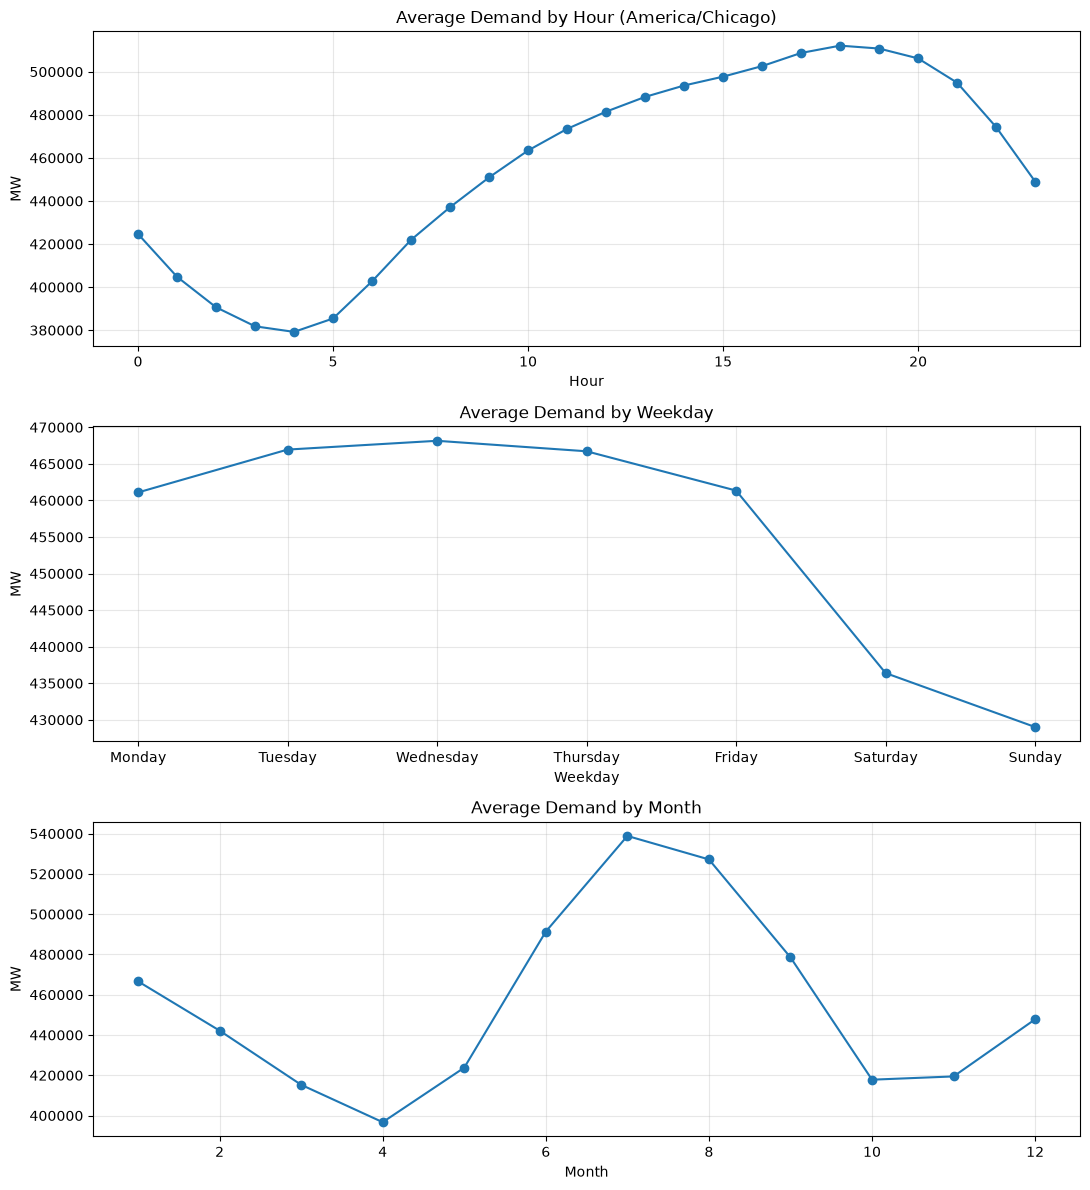

In [7]:
hourly_profile = ts.groupby("hour")["cleaned_demand_mw"].mean()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_profile = ts.groupby("weekday")["cleaned_demand_mw"].mean().reindex(weekday_order)
monthly_profile = ts.groupby("month")["cleaned_demand_mw"].mean().reindex(range(1, 13))

fig, axes = plt.subplots(3, 1, figsize=(11, 12))

hourly_profile.plot(ax=axes[0], marker="o", title="Average Demand by Hour (America/Chicago)")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("MW")
axes[0].grid(True, alpha=0.3)

weekday_profile.plot(ax=axes[1], marker="o", title="Average Demand by Weekday")
axes[1].set_xlabel("Weekday")
axes[1].set_ylabel("MW")
axes[1].grid(True, alpha=0.3)

monthly_profile.plot(ax=axes[2], marker="o", title="Average Demand by Month")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("MW")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 8. DST behavior after timezone conversion

The UTC index is continuous, but local day counts can be 23, 24, or 25 around DST transitions.

Number of non-24-hour local days (interior only): 10
timestamp_utc
2015-11-01 00:00:00-05:00    25
2016-03-13 00:00:00-06:00    23
2016-11-06 00:00:00-05:00    25
2017-03-12 00:00:00-06:00    23
2017-11-05 00:00:00-05:00    25
2018-03-11 00:00:00-06:00    23
2018-11-04 00:00:00-05:00    25
2019-03-10 00:00:00-06:00    23
2019-11-03 00:00:00-05:00    25
2020-03-08 00:00:00-06:00    23
Name: cleaned_demand_mw, dtype: int64


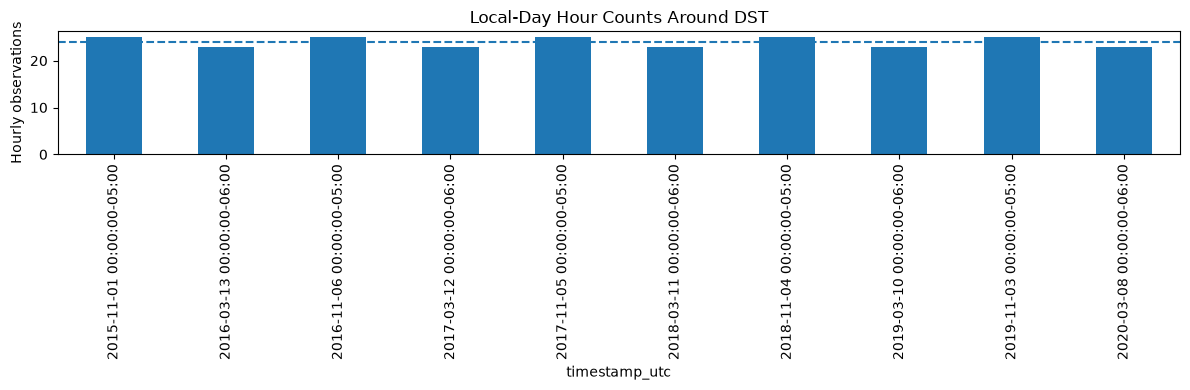

In [9]:
local_series = ts["cleaned_demand_mw"].copy()
local_series.index = local_series.index.tz_convert("America/Chicago")

counts_by_local_day = local_series.resample("D").count()

# Drop boundary days that can be partial due to dataset start/end cutoffs.
inner_counts = counts_by_local_day.iloc[1:-1]
dst_days = inner_counts[inner_counts != 24]

print("Number of non-24-hour local days (interior only):", len(dst_days))
print(dst_days.head(10))

ax = dst_days.plot(kind="bar", figsize=(12, 4), title="Local-Day Hour Counts Around DST")
ax.set_ylabel("Hourly observations")
ax.axhline(24, linestyle="--")
plt.tight_layout()
plt.show()